# Proyek Akhir — Analisis Bike Sharing

**Kelas:** Belajar Fundamental Analisis Data  
**Dataset:** Bike Sharing Dataset — UCI Machine Learning Repository  
**Periode:** 1 Januari 2011–31 Desember 2012  
**Unit analisis utama:** satu baris mewakili satu hari peminjaman.

Proyek ini menjalankan seluruh tahapan analisis data: *gathering*, memahami data, *assessing*, *cleaning*, *Exploratory Data Analysis (EDA)*, visualisasi/*explanatory analysis*, analisis tambahan dengan *binning*, kesimpulan, dan rekomendasi. `day.csv` menjadi sumber utama karena pertanyaan bisnis menggunakan rata-rata peminjaman **per hari**. `hour.csv` tetap disertakan sebagai bagian dataset asli, tetapi tidak digabungkan ke total harian agar transaksi tidak dihitung dua kali.

## Pertanyaan bisnis (SMART)

1. **Tren permintaan:** Bagaimana perubahan rata-rata peminjaman sepeda per hari dari bulan ke bulan sepanjang 2011–2012, dan bulan mana yang perlu menjadi prioritas kesiapan armada atau promosi?
2. **Kondisi operasional:** Seberapa besar perbedaan rata-rata peminjaman harian antara hari kerja dan akhir pekan/hari libur menurut musim dan kondisi cuaca selama 2011–2012, serta segmen mana yang perlu diprioritaskan dalam perencanaan kapasitas?

**Keterkaitan SMART:** kedua pertanyaan berfokus pada tren permintaan dan kondisi operasional (*Specific*), diukur menggunakan rata-rata/jumlah peminjaman (*Measurable*), terkait penjadwalan armada dan operasional (*Action-oriented* dan *Relevant*), serta dibatasi periode 2011–2012 (*Time-bound*).

**Sumber data:** [UCI Machine Learning Repository — Bike Sharing](https://archive.ics.uci.edu/dataset/275/bike%2Bsharing%2Bdataset). Dataset asli merekam penggunaan Capital Bikeshare di Washington, D.C.; temuan di proyek ini bersifat deskriptif untuk periode historis tersebut, bukan klaim kondisi saat ini atau hubungan sebab-akibat.

## 1. Persiapan dan gathering data

**Tujuan:** memuat dataset asli ke dalam DataFrame dan memastikan berkas yang digunakan dapat ditelusuri ke sumbernya.

**Metode:** gunakan `data/day.csv` dari paket dataset UCI. Jika file belum ada, notebook mencoba menjalankan `scripts/download_data.py`. Skrip tersebut mengunduh dataset asli; skrip tidak membuat data sintetis.

**Alasan pemilihan:** `day.csv` berisi satu catatan per hari sehingga langsung sesuai dengan metrik rata-rata peminjaman harian. Dataset mencakup tanggal, musim, kondisi cuaca, tipe hari, pengguna kasual, pengguna terdaftar, dan total peminjaman.

In [1]:
from pathlib import Path
import subprocess
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

ROOT = Path.cwd()
if not (ROOT / "data" / "day.csv").exists() and (ROOT / "scripts" / "download_data.py").exists():
    print("data/day.csv belum ada; mencoba mengunduh dataset resmi...")
    result = subprocess.run([sys.executable, str(ROOT / "scripts" / "download_data.py")], check=False)
    if result.returncode != 0:
        raise FileNotFoundError("Unduhan gagal. Jalankan scripts/download_data.py dengan koneksi internet aktif, lalu jalankan ulang notebook.")

DATA_PATH = ROOT / "data" / "day.csv"
if not DATA_PATH.exists():
    raise FileNotFoundError("File data/day.csv tidak ditemukan. Jalankan python scripts/download_data.py dari root proyek.")

raw_df = pd.read_csv(DATA_PATH)
print(f"Ukuran dataset harian: {raw_df.shape[0]:,} baris × {raw_df.shape[1]} kolom")
print("Kolom:", raw_df.columns.tolist())
display(raw_df.head())

Ukuran dataset harian: 731 baris × 16 kolom
Kolom: ['instant', 'dteday', 'season', 'yr', 'mnth', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed', 'casual', 'registered', 'cnt']


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.34,0.36,0.81,0.16,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.36,0.35,0.70,0.25,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.20,0.19,0.44,0.25,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.20,0.21,0.59,0.16,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.23,0.23,0.44,0.19,82,1518,1600


### Hasil gathering data

Dataset harian asli terdiri dari **731 observasi** dan **16 kolom**, dengan rentang tanggal 1 Januari 2011 sampai 31 Desember 2012. Total `cnt` dalam periode ini adalah **3.292.679 peminjaman**, dengan rata-rata sekitar **4.504 peminjaman per hari**. Angka-angka ini menjadi pemeriksaan kewajaran awal sebelum pembersihan. Tabel contoh di atas dipakai untuk memastikan nama kolom dan bentuk observasi sesuai dengan berkas sumber.

## 2. Memahami data

Tahap ini memeriksa ukuran dataset, nama kolom, tipe data, contoh observasi, dan statistik deskriptif sebelum data dibersihkan. Kolom utama untuk analisis adalah:

- `dteday`: tanggal observasi.
- `cnt`: jumlah total peminjaman per hari; ini merupakan metrik utama proyek.
- `casual` dan `registered`: jumlah peminjaman dari pengguna kasual dan terdaftar.
- `workingday`: penanda hari kerja; nilai 1 berarti hari kerja, sedangkan 0 berarti akhir pekan atau hari libur.
- `season` dan `weathersit`: kode musim dan kondisi cuaca yang perlu diterjemahkan menjadi label.
- `temp`, `atemp`, `hum`, dan `windspeed`: variabel lingkungan yang dinormalisasi. Nilai `temp` tidak langsung dibaca sebagai derajat Celsius.

Statistik deskriptif digunakan untuk memahami skala data, variasi, nilai minimum/maksimum, dan kemungkinan nilai tidak wajar.

In [2]:
raw_df.info()
display(raw_df.describe(include="all").T)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
instant,731.00,NaN,NaN,NaN,366.00,211.17,1.00,183.50,366.00,548.50,731.00
dteday,731,731,2011-01-01,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
season,731.00,NaN,NaN,NaN,2.50,1.11,1.00,2.00,3.00,3.00,4.00
yr,731.00,NaN,NaN,NaN,0.50,0.50,0.00,0.00,1.00,1.00,1.00
mnth,731.00,NaN,NaN,NaN,6.52,3.45,1.00,4.00,7.00,10.00,12.00
holiday,731.00,NaN,NaN,NaN,0.03,0.17,0.00,0.00,0.00,0.00,1.00
weekday,731.00,NaN,NaN,NaN,3.00,2.00,0.00,1.00,3.00,5.00,6.00
workingday,731.00,NaN,NaN,NaN,0.68,0.47,0.00,0.00,1.00,1.00,1.00
weathersit,731.00,NaN,NaN,NaN,1.40,0.54,1.00,1.00,1.00,2.00,3.00
temp,731.00,NaN,NaN,NaN,0.50,0.18,0.06,0.34,0.50,0.66,0.86


### Interpretasi pemahaman data

Tabel informasi tipe data menunjukkan kolom tanggal masih berupa teks pada saat pembacaan CSV; ini ditangani pada tahap cleaning. `cnt` merupakan jumlah total harian, sehingga tidak dijumlahkan lagi dengan file `hour.csv`. Kolom lingkungan telah dinormalisasi, maka perbandingan nilai `temp` pada analisis tambahan menggunakan kelompok skala relatif dan bukan klaim suhu dalam derajat Celsius.

## 3. Assessing data

**Tujuan:** menilai kualitas data sebelum memilih tindakan pembersihan. Pemeriksaan dilakukan untuk:

1. *Missing values* pada setiap kolom.
2. Baris duplikat penuh.
3. Tipe data tanggal yang belum sesuai.
4. Kode kategori yang berada di luar daftar nilai yang diperbolehkan.
5. Nilai ekstrem pada kolom peminjaman dengan metode *Interquartile Range* (IQR).

Batas IQR dihitung sebagai `Q1 - 1.5 × IQR` dan `Q3 + 1.5 × IQR`. Penanda outlier adalah sinyal untuk investigasi, bukan instruksi otomatis untuk membuang baris, karena puncak permintaan bisa merupakan kejadian yang valid.

In [3]:
assessment = pd.DataFrame({
    "missing_values": raw_df.isna().sum(),
    "data_type": raw_df.dtypes.astype(str),
    "unique_values": raw_df.nunique(dropna=True),
})
display(assessment)
print("Jumlah baris duplikat seluruh kolom:", int(raw_df.duplicated().sum()))
if "dteday" in raw_df.columns:
    print("Tipe awal dteday:", raw_df["dteday"].dtype, "| contoh:", raw_df["dteday"].head(3).tolist())

allowed = {
    "season": {1, 2, 3, 4},
    "yr": {0, 1},
    "mnth": set(range(1, 13)),
    "weekday": set(range(0, 7)),
    "workingday": {0, 1},
    "holiday": {0, 1},
    "weathersit": {1, 2, 3, 4},
}
invalid_report = {}
for column, values in allowed.items():
    if column in raw_df.columns:
        observed = set(pd.to_numeric(raw_df[column], errors="coerce").dropna().unique())
        invalid_report[column] = sorted(observed - values)
print("Kode kategori di luar nilai yang diperbolehkan:")
display(pd.Series(invalid_report, name="invalid_codes").to_frame())

# IQR assessment for demand variables. Outlier detection is a flag for investigation,
# not an automatic instruction to delete a valid peak-demand day.
iqr_rows = []
for column in ["cnt", "casual", "registered"]:
    if column not in raw_df:
        continue
    q1 = raw_df[column].quantile(0.25)
    q3 = raw_df[column].quantile(0.75)
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_outliers = int(((raw_df[column] < lower) | (raw_df[column] > upper)).sum())
    iqr_rows.append({"kolom": column, "Q1": q1, "Q3": q3, "IQR": iqr,
                     "batas_bawah": lower, "batas_atas": upper,
                     "jumlah_outlier": n_outliers})
iqr_report = pd.DataFrame(iqr_rows)
display(iqr_report)

,missing_values,data_type,unique_values
instant,0,int64,731
dteday,0,object,731
season,0,int64,4
yr,0,int64,2
mnth,0,int64,12
holiday,0,int64,2
weekday,0,int64,7
workingday,0,int64,2
weathersit,0,int64,3
temp,0,float64,499


Jumlah baris duplikat seluruh kolom: 0
Tipe awal dteday: object | contoh: ['2011-01-01', '2011-01-02', '2011-01-03']
Kode kategori di luar nilai yang diperbolehkan:


,invalid_codes
season,[]
yr,[]
mnth,[]
weekday,[]
workingday,[]
holiday,[]
weathersit,[]


,kolom,Q1,Q3,IQR,batas_bawah,batas_atas,jumlah_outlier
0,cnt,"3,152.00","5,956.00","2,804.00","-1,054.00","10,162.00",0
1,casual,315.50,"1,096.00",780.50,-855.25,"2,266.75",44
2,registered,"2,497.00","4,776.50","2,279.50",-922.25,"8,195.75",0


### Temuan assessment dan keputusan cleaning

Pada dataset harian asli UCI yang digunakan untuk proyek ini, pemeriksaan kualitas menunjukkan **tidak ada missing value, tidak ada baris duplikat identik, dan tidak ditemukan kode kategori di luar rentang yang diizinkan**. Kolom `dteday` pada file CSV awal terbaca sebagai teks, sehingga tetap perlu dikonversi menjadi tipe tanggal agar dapat dikelompokkan menurut bulan dan tahun.

Tabel IQR di atas digunakan untuk mengidentifikasi nilai peminjaman yang perlu ditinjau. Nilai ekstrem pada pengguna kasual tidak langsung dihapus hanya karena berada di luar batas IQR; keputusan penghapusan membutuhkan konteks tambahan dan dapat menghilangkan hari dengan permintaan tinggi yang sah.

## 4. Cleaning data

Pembersihan mengikuti hasil assessment dan menerapkan perubahan yang relevan saja:

- Mengonversi `dteday` menjadi tipe tanggal.
- Menghapus hanya baris duplikat yang identik.
- Mengonversi kolom numerik utama ke format numerik; nilai yang tidak dapat dikonversi akan menjadi missing value sehingga dapat dikenali.
- Mengeluarkan baris yang tanggal atau target `cnt`-nya tidak valid, karena baris tersebut tidak dapat dipakai untuk analisis harian.
- Menambahkan label yang mudah dibaca untuk musim, cuaca, hari dalam seminggu, tahun, dan bulan.

Tidak dilakukan imputasi angka peminjaman karena menebak jumlah transaksi dapat mengubah kesimpulan. Jumlah baris sebelum dan sesudah pembersihan dicetak agar dampak cleaning dapat diaudit.

In [4]:
df = raw_df.copy()
rows_before = len(df)
if "dteday" in df.columns:
    df["dteday"] = pd.to_datetime(df["dteday"], errors="coerce")
duplicates_removed = int(df.duplicated().sum())
df = df.drop_duplicates().copy()

numeric_columns = [c for c in ["instant", "season", "yr", "mnth", "holiday", "weekday",
                               "workingday", "weathersit", "temp", "atemp", "hum",
                               "windspeed", "casual", "registered", "cnt"] if c in df.columns]
for column in numeric_columns:
    df[column] = pd.to_numeric(df[column], errors="coerce")

rows_before_target_filter = len(df)
df = df.dropna(subset=["dteday", "cnt"]).copy()
invalid_target_rows_removed = rows_before_target_filter - len(df)

season_map = {1: "Semi", 2: "Panas", 3: "Gugur", 4: "Dingin"}
weather_map = {
    1: "Cerah / sedikit awan",
    2: "Berkabut / berawan",
    3: "Hujan ringan / salju ringan",
    4: "Cuaca ekstrem",
}
weekday_map = {0: "Minggu", 1: "Senin", 2: "Selasa", 3: "Rabu", 4: "Kamis", 5: "Jumat", 6: "Sabtu"}
if "season" in df:
    df["season_name"] = df["season"].map(season_map).fillna("Kode tidak diketahui")
if "weathersit" in df:
    df["weather_name"] = df["weathersit"].map(weather_map).fillna("Kode tidak diketahui")
if "weekday" in df:
    df["weekday_name"] = df["weekday"].map(weekday_map).fillna("Kode tidak diketahui")
if "workingday" in df:
    df["day_type"] = df["workingday"].map({1: "Hari kerja", 0: "Akhir pekan / hari libur"}).fillna("Tidak diketahui")

df["year"] = df["dteday"].dt.year
df["month"] = df["dteday"].dt.month
df["month_start"] = df["dteday"].dt.to_period("M").dt.to_timestamp()
df["month_name"] = df["dteday"].dt.strftime("%b")

print(f"Baris awal: {rows_before:,}")
print(f"Duplikat identik dihapus: {duplicates_removed:,}")
print(f"Baris tanpa tanggal/target valid yang dihapus: {invalid_target_rows_removed:,}")
print(f"Baris bersih: {len(df):,}")
display(df.head())

Baris awal: 731
Duplikat identik dihapus: 0
Baris tanpa tanggal/target valid yang dihapus: 0
Baris bersih: 731


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt,season_name,weather_name,weekday_name,day_type,year,month,month_start,month_name
0,1,2011-01-01,1,0,1,0,6,0,2,0.34,0.36,0.81,0.16,331,654,985,Semi,Berkabut / berawan,Sabtu,Akhir pekan / hari libur,2011,1,2011-01-01,Jan
1,2,2011-01-02,1,0,1,0,0,0,2,0.36,0.35,0.70,0.25,131,670,801,Semi,Berkabut / berawan,Minggu,Akhir pekan / hari libur,2011,1,2011-01-01,Jan
2,3,2011-01-03,1,0,1,0,1,1,1,0.20,0.19,0.44,0.25,120,1229,1349,Semi,Cerah / sedikit awan,Senin,Hari kerja,2011,1,2011-01-01,Jan
3,4,2011-01-04,1,0,1,0,2,1,1,0.20,0.21,0.59,0.16,108,1454,1562,Semi,Cerah / sedikit awan,Selasa,Hari kerja,2011,1,2011-01-01,Jan
4,5,2011-01-05,1,0,1,0,3,1,1,0.23,0.23,0.44,0.19,82,1518,1600,Semi,Cerah / sedikit awan,Rabu,Hari kerja,2011,1,2011-01-01,Jan


### Hasil cleaning data

Untuk berkas harian asli yang digunakan, jumlah baris tetap **731** setelah cleaning: tidak ada baris duplikat identik yang perlu dihapus dan tidak ada baris yang dikeluarkan karena tanggal atau `cnt` yang hilang/tidak valid. Perubahan penting adalah mengonversi tanggal ke format `datetime` dan menambahkan kolom turunan untuk tahun, bulan, serta label kategori. Baris ekstrem yang valid dipertahankan agar tidak menghilangkan informasi tentang lonjakan permintaan.

## 5. EDA — ringkasan statistik dan pola umum

**Tujuan:** menjawab dua pertanyaan bisnis menggunakan statistik deskriptif, pengelompokan, dan agregasi.

- Ringkasan numerik membantu memahami distribusi jumlah peminjaman dan variabel lingkungan.
- `monthly` menghitung rata-rata dan total peminjaman serta jumlah hari pada setiap bulan untuk menjawab pertanyaan bisnis 1.
- `season_summary` membandingkan rata-rata, median, dan total peminjaman per musim.
- `operation_summary` membandingkan rata-rata peminjaman untuk kombinasi tipe hari, musim, dan cuaca. Tabel ini digunakan untuk mengidentifikasi segmen operasional yang perlu diprioritaskan.

Rata-rata dipakai untuk membandingkan tingkat permintaan harian, sedangkan jumlah hari pada tiap grup membantu memberi konteks ukuran sampel.

In [5]:
display(df[[c for c in ["casual", "registered", "cnt", "temp", "atemp", "hum", "windspeed"] if c in df]].describe().T)

monthly = (df.groupby(["year", "month", "month_start"], as_index=False)
             .agg(avg_daily_rentals=("cnt", "mean"), total_rentals=("cnt", "sum"), days=("cnt", "size"))
             .sort_values("month_start"))
display(monthly.head(12))

season_summary = (df.groupby("season_name", as_index=False)
                    .agg(avg_daily_rentals=("cnt", "mean"), median_daily_rentals=("cnt", "median"),
                         total_rentals=("cnt", "sum"), days=("cnt", "size"))
                    .sort_values("avg_daily_rentals", ascending=False))
display(season_summary)

operation_summary = (df.groupby(["day_type", "season_name", "weather_name"], as_index=False)
                       .agg(avg_daily_rentals=("cnt", "mean"), median_daily_rentals=("cnt", "median"),
                            days=("cnt", "size"))
                       .sort_values("avg_daily_rentals", ascending=False))
display(operation_summary.head(15))

,count,mean,std,min,25%,50%,75%,max
casual,731.00,848.18,686.62,2.00,315.50,713.00,"1,096.00","3,410.00"
registered,731.00,"3,656.17","1,560.26",20.00,"2,497.00","3,662.00","4,776.50","6,946.00"
cnt,731.00,"4,504.35","1,937.21",22.00,"3,152.00","4,548.00","5,956.00","8,714.00"
temp,731.00,0.50,0.18,0.06,0.34,0.50,0.66,0.86
atemp,731.00,0.47,0.16,0.08,0.34,0.49,0.61,0.84
hum,731.00,0.63,0.14,0.00,0.52,0.63,0.73,0.97
windspeed,731.00,0.19,0.08,0.02,0.13,0.18,0.23,0.51


,year,month,month_start,avg_daily_rentals,total_rentals,days
0,2011,1,2011-01-01,"1,231.90",38189,31
1,2011,2,2011-02-01,"1,721.96",48215,28
2,2011,3,2011-03-01,"2,065.97",64045,31
3,2011,4,2011-04-01,"3,162.33",94870,30
4,2011,5,2011-05-01,"4,381.32",135821,31
5,2011,6,2011-06-01,"4,783.73",143512,30
6,2011,7,2011-07-01,"4,559.39",141341,31
7,2011,8,2011-08-01,"4,409.39",136691,31
8,2011,9,2011-09-01,"4,247.27",127418,30
9,2011,10,2011-10-01,"3,984.23",123511,31


,season_name,avg_daily_rentals,median_daily_rentals,total_rentals,days
1,Gugur,"5,644.30","5,353.50",1061129,188
2,Panas,"4,992.33","4,941.50",918589,184
0,Dingin,"4,728.16","4,634.50",841613,178
3,Semi,"2,604.13","2,209.00",471348,181


,day_type,season_name,weather_name,avg_daily_rentals,median_daily_rentals,days
16,Hari kerja,Gugur,Cerah / sedikit awan,"5,961.24","5,895.00",97
7,Akhir pekan / hari libur,Panas,Cerah / sedikit awan,"5,821.19","6,080.50",36
4,Akhir pekan / hari libur,Gugur,Cerah / sedikit awan,"5,671.87","5,336.00",39
19,Hari kerja,Panas,Cerah / sedikit awan,"5,421.08","5,409.00",77
15,Hari kerja,Gugur,Berkabut / berawan,"5,299.52","4,790.00",31
13,Hari kerja,Dingin,Cerah / sedikit awan,"5,213.84","5,146.00",63
3,Akhir pekan / hari libur,Gugur,Berkabut / berawan,"5,082.00","5,255.00",17
1,Akhir pekan / hari libur,Dingin,Cerah / sedikit awan,"4,775.38","4,525.00",40
12,Hari kerja,Dingin,Berkabut / berawan,"4,726.49","4,563.00",49
5,Akhir pekan / hari libur,Gugur,Hujan ringan / salju ringan,"4,459.00","4,459.00",1


### Insight dari EDA

Ringkasan bulanan memperlihatkan kenaikan permintaan dari awal tahun menuju sekitar Agustus–September, kemudian penurunan di penghujung tahun. Dalam agregasi bulanan, September 2012 menjadi bulan dengan rata-rata harian tertinggi (sekitar 7.286), sedangkan Januari 2011 terendah (sekitar 1.232).

Pada perbandingan musim, rata-rata tertinggi berada pada musim Gugur (sekitar 5.644 peminjaman/hari) dan terendah pada musim Semi (sekitar 2.604 peminjaman/hari). Rata-rata hari kerja sekitar 4.585, sementara akhir pekan/hari libur sekitar 4.330. Ringkasan cuaca menunjukkan rata-rata lebih tinggi saat cerah/sedikit awan (sekitar 4.877) dan lebih rendah saat hujan ringan/salju ringan (sekitar 1.803). Gunakan tabel kombinasi `operation_summary` untuk melihat kelompok operasional yang lebih spesifik.

## 6. Visualization & explanatory analysis

Visualisasi mengomunikasikan temuan dari EDA dan setiap pertanyaan bisnis mendapat visual yang relevan:

1. **Grafik garis rata-rata bulanan** menjawab pertanyaan bisnis 1 dengan menunjukkan perubahan permintaan dari Januari 2011 sampai Desember 2012.
2. **Grafik batang hari kerja vs. non-hari kerja menurut musim** membandingkan tingkat permintaan antarsegmen untuk pertanyaan bisnis 2.
3. **Grafik batang berdasarkan cuaca** melengkapi analisis kondisi operasional.

Grafik menggunakan judul dan label sumbu yang menjelaskan metrik, satuan konsisten (peminjaman per hari), dan skala yang tidak dipotong secara menyesatkan. Grafik bersifat deskriptif: perbedaan rata-rata tidak dengan sendirinya membuktikan bahwa musim atau cuaca menyebabkan perubahan permintaan.

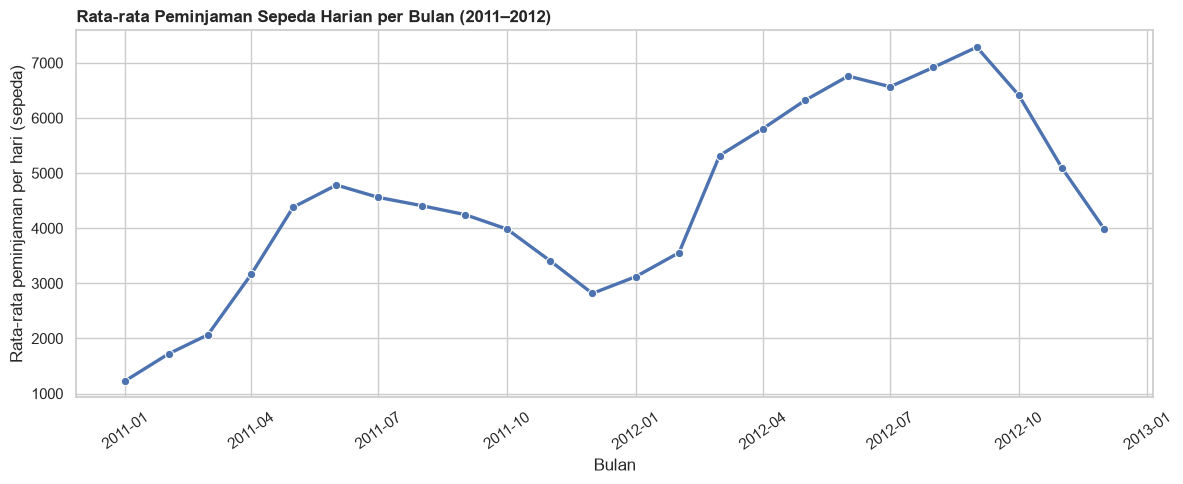

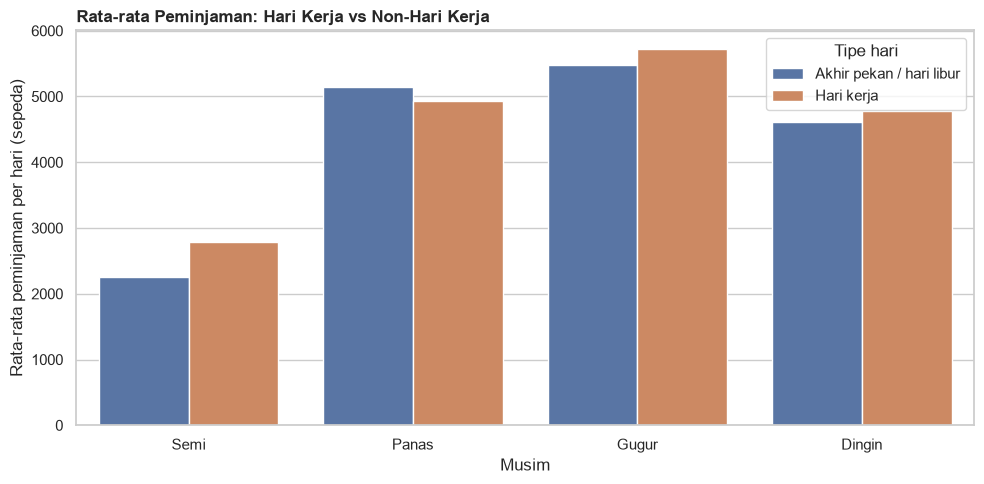

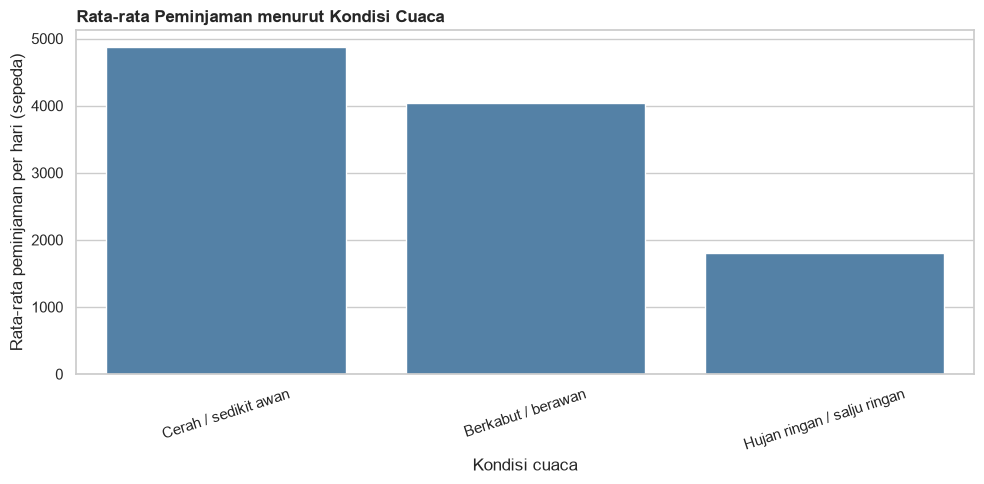

In [6]:
sns.set_theme(style="whitegrid", context="notebook")

# Visual 1: average daily rentals by month across 2011–2012 (business question 1)
fig, ax = plt.subplots(figsize=(12, 5))
sns.lineplot(data=monthly, x="month_start", y="avg_daily_rentals", marker="o", linewidth=2.4, ax=ax)
ax.set_title("Rata-rata Peminjaman Sepeda Harian per Bulan (2011–2012)", loc="left", weight="bold")
ax.set_xlabel("Bulan")
ax.set_ylabel("Rata-rata peminjaman per hari (sepeda)")
ax.tick_params(axis="x", rotation=35)
fig.tight_layout()
plt.show()

# Visual 2: demand by day type and season (business question 2)
fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=df, x="season_name", y="cnt", hue="day_type", estimator="mean", errorbar=None, palette="deep", ax=ax)
ax.set_title("Rata-rata Peminjaman: Hari Kerja vs Non-Hari Kerja", loc="left", weight="bold")
ax.set_xlabel("Musim")
ax.set_ylabel("Rata-rata peminjaman per hari (sepeda)")
ax.legend(title="Tipe hari")
fig.tight_layout()
plt.show()

# Supporting visualization: weather context
weather_summary = df.groupby("weather_name", as_index=False)["cnt"].mean().sort_values("cnt", ascending=False)
fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=weather_summary, x="weather_name", y="cnt", ax=ax, errorbar=None, color="steelblue")
ax.set_title("Rata-rata Peminjaman menurut Kondisi Cuaca", loc="left", weight="bold")
ax.set_xlabel("Kondisi cuaca")
ax.set_ylabel("Rata-rata peminjaman per hari (sepeda)")
ax.tick_params(axis="x", rotation=18)
fig.tight_layout()
plt.show()

### Interpretasi visualisasi (*explanatory analysis*)

- **Grafik garis bulanan:** naik-turunnya garis menunjukkan pola musiman tahunan. Puncak September 2012 dan nilai rendah Januari 2011 mendukung perlunya rencana kapasitas yang berubah mengikuti waktu.
- **Grafik batang tipe hari dan musim:** membantu membandingkan rata-rata antarjenis hari di masing-masing musim; perbedaan yang kecil atau besar perlu dilihat bersama konteks kelompoknya, bukan hanya total keseluruhan.
- **Grafik cuaca:** rata-rata peminjaman paling rendah pada kondisi hujan ringan/salju ringan. Hal ini dapat dipakai untuk perencanaan operasional, tetapi hubungan sebab-akibat tidak diuji di proyek ini.

Ketiga visualisasi melengkapi tabel EDA dan menjawab dua pertanyaan bisnis melalui metrik kuantitatif.

## 7. Analisis tambahan — binning suhu

Sebagai teknik analisis lanjutan tanpa machine learning, nilai `temp` yang telah dinormalisasi dibagi menjadi empat interval: sangat rendah, rendah–sedang, sedang–tinggi, dan tinggi. Tujuannya adalah membandingkan rata-rata peminjaman di kelompok suhu yang berbeda dengan aturan yang transparan.

Ambang 0,25; 0,50; dan 0,75 adalah batas pada skala normalisasi, bukan batas suhu Celsius. Hasil kelompok ditampilkan dalam tabel dan grafik. Interpretasikan hasil sebagai pola asosiasi; variabel lain seperti musim, hari kerja, dan cuaca juga dapat berhubungan dengan permintaan.

,temp_group,avg_daily_rentals,median_daily_rentals,days
0,Sangat rendah,"1,703.17","1,538.00",63
1,Rendah–sedang,"3,758.45","3,733.50",304
2,Sedang–tinggi,"5,647.10","5,336.00",311
3,Tinggi,"5,406.79","5,463.00",53


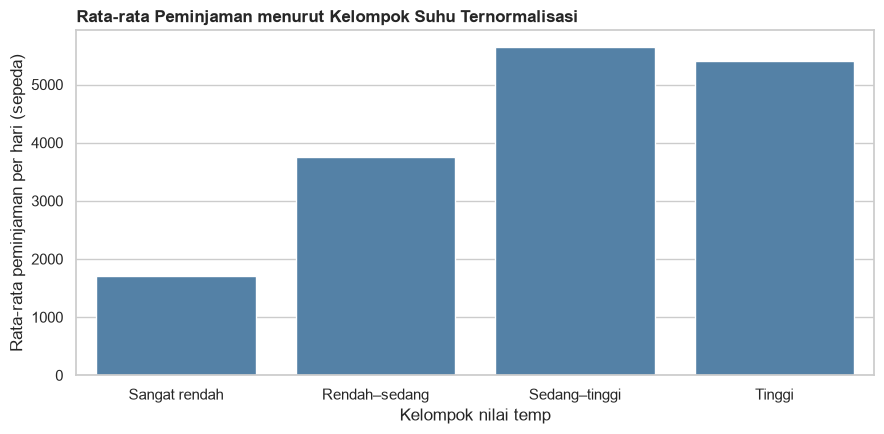

In [7]:
if "temp" in df.columns:
    bin_edges = [-np.inf, 0.25, 0.50, 0.75, np.inf]
    bin_labels = ["Sangat rendah", "Rendah–sedang", "Sedang–tinggi", "Tinggi"]
    df["temp_group"] = pd.cut(df["temp"], bins=bin_edges, labels=bin_labels, include_lowest=True)
    temp_summary = (df.groupby("temp_group", observed=False, as_index=False)
                      .agg(avg_daily_rentals=("cnt", "mean"), median_daily_rentals=("cnt", "median"), days=("cnt", "size")))
    display(temp_summary)
    fig, ax = plt.subplots(figsize=(9, 4.5))
    sns.barplot(data=temp_summary, x="temp_group", y="avg_daily_rentals", ax=ax, errorbar=None, color="steelblue")
    ax.set_title("Rata-rata Peminjaman menurut Kelompok Suhu Ternormalisasi", loc="left", weight="bold")
    ax.set_xlabel("Kelompok nilai temp")
    ax.set_ylabel("Rata-rata peminjaman per hari (sepeda)")
    fig.tight_layout()
    plt.show()

### Insight analisis binning

Tabel dan grafik binning membandingkan permintaan rata-rata untuk empat rentang `temp` ternormalisasi. Bacalah perbedaan antarkelompok sebagai indikasi pola hubungan antara temperatur relatif dan permintaan. Binning mudah dijelaskan serta tidak memakai algoritma machine learning. Karena suhu, musim, dan kondisi cuaca saling berkaitan, hasil ini tidak cukup untuk menyatakan bahwa perubahan suhu sendirian menyebabkan perubahan permintaan.

## 8. Menyimpan data bersih untuk dashboard

Data bersih diekspor ke `dashboard/main_data.csv` agar aplikasi Streamlit menggunakan sumber harian dan label kategori yang sama seperti notebook. Langkah ini menjaga konsistensi antara analisis tertulis dan dashboard.

In [8]:
dashboard_dir = ROOT / "dashboard"
dashboard_dir.mkdir(exist_ok=True)
export_columns = [c for c in df.columns if c not in ["temp_group"]]
df[export_columns].to_csv(dashboard_dir / "main_data.csv", index=False)
print(f"Data bersih disimpan ke {dashboard_dir / 'main_data.csv'}")
print("Sebelum submission, simpan notebook setelah seluruh sel berhasil dijalankan dan periksa grafik serta rangkuman angka.")

Data bersih disimpan ke C:\Users\PIH\Downloads\bike_sharing_submission\dashboard\main_data.csv
Sebelum submission, simpan notebook setelah seluruh sel berhasil dijalankan dan periksa grafik serta rangkuman angka.


## 9. Conclusion & recommendation

### Kesimpulan 1 — Menjawab pertanyaan bisnis 1: tren permintaan bulanan

Rata-rata peminjaman harian menunjukkan pola musiman yang jelas sepanjang 2011–2012: permintaan relatif rendah pada awal tahun, meningkat menuju pertengahan hingga akhir tahun, lalu kembali menurun menjelang akhir tahun. Berdasarkan agregasi bulanan dataset harian, **rata-rata tertinggi terjadi pada September 2012, sekitar 7.286 peminjaman per hari**, sedangkan **rata-rata terendah terjadi pada Januari 2011, sekitar 1.232 peminjaman per hari**. Temuan ini menunjukkan bahwa perencanaan armada sebaiknya mengikuti pola musiman, bukan menggunakan kapasitas yang sama sepanjang tahun.

### Kesimpulan 2 — Menjawab pertanyaan bisnis 2: tipe hari, musim, dan cuaca

Rata-rata peminjaman pada **hari kerja sekitar 4.585 per hari**, sedikit lebih tinggi daripada **akhir pekan/hari libur sekitar 4.330 per hari**. Jika dibandingkan menurut musim, **musim Gugur memiliki rata-rata tertinggi (sekitar 5.644 peminjaman per hari)**, sedangkan **musim Semi memiliki rata-rata terendah (sekitar 2.604 per hari)**. Pada kelompok kondisi cuaca, rata-rata tertinggi ditemukan pada kondisi **Cerah/sedikit awan (sekitar 4.877 per hari)**; kondisi **Berkabut/berawan sekitar 4.036 per hari**, sedangkan **hujan ringan/salju ringan sekitar 1.803 per hari**. Perbandingan kombinasi tipe hari–musim–cuaca dapat dilihat lebih rinci pada tabel `operation_summary` di bagian EDA. Hasil ini menggambarkan asosiasi dalam data historis, bukan bukti sebab-akibat.

### Rekomendasi action item

1. **Rencanakan kesiapan armada dan pemeliharaan sebelum periode permintaan tinggi**, khususnya menjelang akhir musim panas hingga musim Gugur. Gunakan perkiraan bulanan sebagai acuan awal, lalu sesuaikan dengan data operasional terbaru.
2. **Atur staf dan ketersediaan armada secara fleksibel** berdasarkan tipe hari, musim, dan cuaca. Siapkan rencana kapasitas alternatif untuk kondisi hujan.
3. **Uji promosi secara terukur pada periode permintaan rendah**, lalu evaluasi hasilnya menggunakan perubahan rata-rata peminjaman harian. Jangan menganggap perbedaan historis sebagai jaminan hasil promosi.
4. **Selidiki nilai ekstrem sebelum menghapus data** agar puncak permintaan yang valid tetap terwakili dalam perencanaan.

**Batasan analisis:** dataset mencakup Capital Bikeshare pada 2011–2012 saja. Temuan ini cocok untuk memahami pola historis dalam dataset tersebut; jangan menganggapnya sebagai gambaran permintaan saat ini atau langsung menggeneralisasikannya ke kota/sistem lain.

### Ringkasan akhir

Dua pertanyaan bisnis telah dijawab secara berurutan: **(1)** permintaan bulanan berfluktuasi secara musiman dengan puncak pada September 2012 dan titik rendah pada Januari 2011; **(2)** rata-rata berbeda menurut tipe hari, musim, dan kondisi cuaca. Rekomendasi utama adalah menyesuaikan kesiapan armada, pemeliharaan, dan staf terhadap pola musiman serta kondisi operasional, kemudian mengevaluasi tindakan menggunakan metrik peminjaman harian.

Sebelum submission, jalankan seluruh sel dari awal sampai akhir, pastikan tidak ada error, simpan notebook dengan `Ctrl+S`, dan pastikan output tabel/grafik tersimpan dalam berkas `.ipynb`.